In [10]:
import numpy as np
import pylab as plt
import jax
import jax.numpy as jnp

In [7]:
# load the images from the .npz file
data = np.load("celeba_1000.npz")
images_arr = data["images"]

# load the male annotations from the .npz file
data = np.load("male_1000.npz")
male_arr = data["male"]

# number of images
n = images_arr.shape[0]
print(images_arr.shape)
print("Number of images:", n)

(1000, 96, 96)
Number of images: 1000


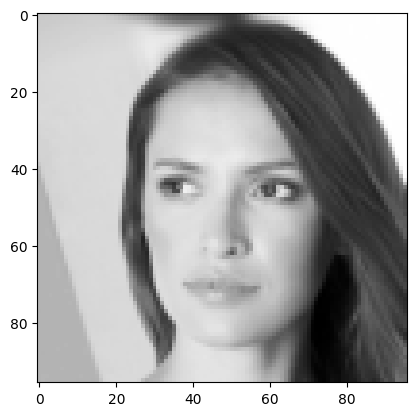

In [6]:
plt.imshow(images_arr[0,:,:],cmap='grey')

In [30]:
#plt.imshow(np.mean(images_arr), cmap='grey')

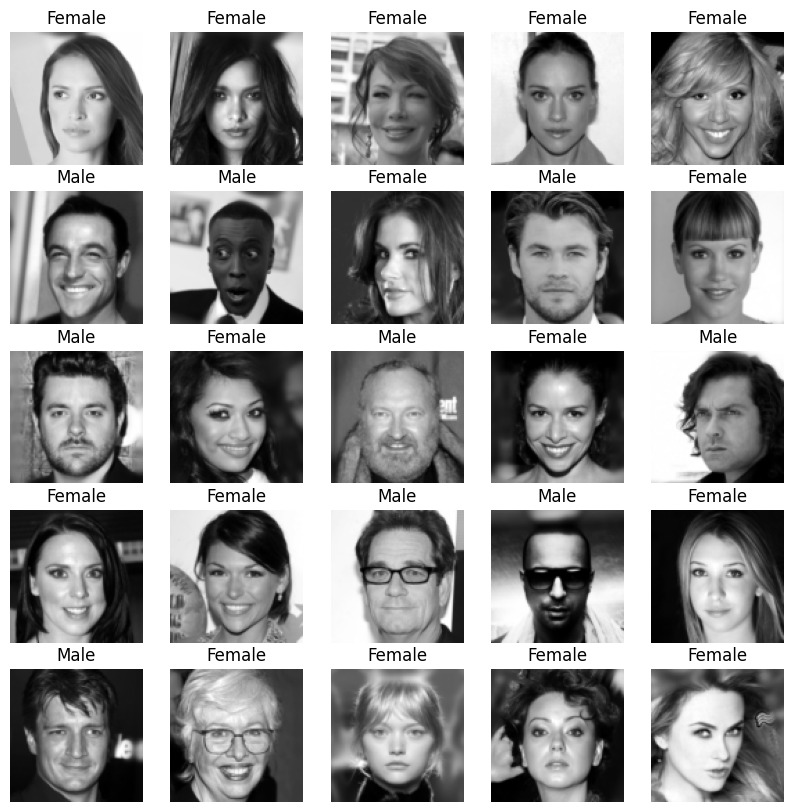

In [4]:
# plot the the first 25 images in a 5x5 grid
fig, ax = plt.subplots(5,5, figsize=(10,10))
for i in range(5):
    for j in range(5):
        ax[i,j].imshow(images_arr[i*5+j], cmap="gray")
        ax[i,j].axis("off")
        
        # as a title, use Male/Female stored in sex_arr
        male = male_arr[i*5+j]
        title = "Male" if male == 1 else "Female"
        ax[i,j].set_title(title)
        
plt.show()

In [11]:
image_flat = images_arr.reshape(1000,-1)
_, dim = image_flat.shape

In [17]:
# extract the dimensions of the images
n_samples, height, width = images_arr.shape

# flatten the images
X = images_arr.reshape(n_samples, height*width)

# target vector
label = male_arr

In [6]:
# task: use the first 800 samples for training and the last 200 for testing
# and use gradient descent to train a logistic regression model
# Once done, compute the accuracy on the test and training set

In [18]:
#implement loss function
def local_loss(beta, #vector of parameters
                image, #single image represented a a long vector
                label, #{-1,+1}
                ): 
    return jnp.log(1.+jnp.exp(-label*jnp.dot(beta, image)))

In [23]:
beta_init=np.random.normal(0,1,size=dim)/np.sqrt(dim)
local_loss(beta_init, image_flat[0],label[0])

Array(1.3872763, dtype=float32)

In [28]:
#vamp
loss_all=jax.vmap(local_loss, in_axes=(None,0,0)) #parallelize across images & labels

#average loss
@jax.jit
def loss(beta, image, label):   
    return jnp.mean(loss_all(beta,image,label))

loss(beta_init, image_flat, label)

Array(0.92616385, dtype=float32)

In [31]:
#gradient of the loss
loss_value_and_grad=jax.jit(jax.value_and_grad(loss))

In [37]:
#logistic regression: gradient descent

beta=np.copy(beta_init)
lr=0.005
niter=1000
loss_history=[]

for it in range(niter):
    v,g=loss_value_and_grad(beta,image_flat,label)
    beta=beta-lr*g
    loss_history.append(v)
    
    if it%50 == 0:
        print(f"iteration:{it}\t loss={v:2.4f}")

iteration:0	 loss=0.9262
iteration:50	 loss=0.5434
iteration:100	 loss=0.4958
iteration:150	 loss=0.4689
iteration:200	 loss=0.4479
iteration:250	 loss=0.4306
iteration:300	 loss=0.4157
iteration:350	 loss=0.4027
iteration:400	 loss=0.3912
iteration:450	 loss=0.3808
iteration:500	 loss=0.3714
iteration:550	 loss=0.3627
iteration:600	 loss=0.3548
iteration:650	 loss=0.3473
iteration:700	 loss=0.3404
iteration:750	 loss=0.3339
iteration:800	 loss=0.3279
iteration:850	 loss=0.3221
iteration:900	 loss=0.3167
iteration:950	 loss=0.3115


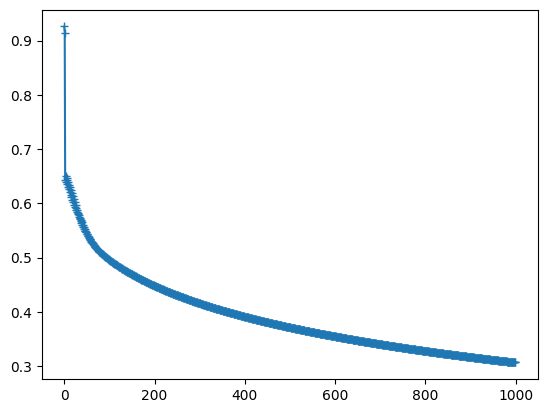

In [38]:
plt.plot(loss_history,"-+")

In [40]:
#make prediction
def prediction_local(beta, image):
    prob = 1./(1+jnp.exp(-jnp.dot(beta, image)))
    return prob


make_predictions=jax.vmap(prediction_local, in_axes=(None,0))

In [46]:
prediction_male=( make_predictions(beta, image_flat) > 0.5 )
male_true = (label == 1)
accuracy = jnp.mean( prediction_male ==  male_true)
print(f"Accuracy of the model: {100*accuracy:2.2f}%")

Accuracy of the model: 89.90%


In [ ]:
#evaluation